<a href="https://colab.research.google.com/github/Vykhrystenko/ML_FIT_3-9_Vykhrystenko/blob/main/%D0%9B%D0%A0_11_CNN_Fashion_MNIST_%D0%92%D0%B8%D1%85%D1%80%D0%B8%D1%81%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_3_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота: Згорткова нейронна мережа для класифікації Fashion-MNIST

**ПІБ студента:** Вихристенко В. О.  
**Група:** 3-9  
**Дата:** 20.11.2026

### Мета роботи
Навчитися завантажувати та готувати зображення для класифікації, будувати згорткову нейронну мережу (CNN) засобами **TensorFlow / Keras**, навчати її та аналізувати результати.

### Завдання
На основі послідовності кроків у цьому шаблоні самостійно реалізуйте класифікацію зображень одягу з набору **Fashion-MNIST** (10 класів, зображення 28 × 28 пікселів). Усі комірки для коду залишено порожніми.

**Вимоги до здачі:** заповнений та виконаний `.ipynb` із виводами, графіками, прикладами прогнозів і власними висновками.

## 1. Імпорт бібліотек
Імпортуйте TensorFlow, NumPy, Matplotlib, а також потрібні модулі Keras: `Sequential`, `Input`, `Conv2D`, `MaxPooling2D`, `Dropout`, `Flatten`, `Dense`, `BatchNormalization`, `EarlyStopping`, `ReduceLROnPlateau`, `fashion_mnist`, `to_categorical`.

У вихідному прикладі також імпортовано `ImageDataGenerator`; у цій роботі він не використовується, тому його застосування необов’язкове.

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dropout, Flatten, Dense, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical

## 2. Завантаження даних
Завантажте **Fashion-MNIST** за допомогою `fashion_mnist.load_data()`. Збережіть навчальну та тестову вибірки у змінні `x_train`, `y_train`, `x_test`, `y_test`.

Виведіть розміри масивів, кількість класів і тип значень пікселів.

In [ ]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print("Розмір x_train:", x_train.shape)
print("Розмір y_train:", y_train.shape)
print("Розмір x_test:", x_test.shape)
print("Розмір y_test:", y_test.shape)
print("Кількість класів:", len(np.unique(y_train)))
print("Тип значень пікселів:", x_train.dtype)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Розмір x_train: (60000, 28, 28)
Розмір y_train: (60000,)
Розмір x_test: (10000, 28, 28)
Розмір y_test: (10000,)
Кількість класів: 10
Тип значень пікселів: uint8


## 3. Підготовка зображень
Додайте до зображень вимір каналу: початкова форма окремого зображення `(28, 28)` повинна стати `(28, 28, 1)`. Використайте `np.expand_dims()` або еквівалентну операцію.

Перевірте результат за допомогою `.shape`.

In [ ]:
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Форма x_train після додавання каналу:", x_train.shape)
print("Форма x_test після додавання каналу:", x_test.shape)

Форма x_train після додавання каналу: (60000, 28, 28, 1)
Форма x_test після додавання каналу: (10000, 28, 28, 1)


## 4. Нормалізація і кодування міток
Переведіть пікселі в тип `float32` і масштабуйте їх до діапазону **[0, 1]**. Перетворіть мітки класів на категоріальний формат за допомогою `to_categorical(..., 10)`.

Збережіть закодовані мітки як `y_train_cat` та `y_test_cat`. Перевірте діапазон пікселів і форму міток.

In [ ]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Діапазон пікселів x_train:", x_train.min(), "—", x_train.max())
print("Форма y_train_cat:", y_train_cat.shape)
print("Форма y_test_cat:", y_test_cat.shape)

Діапазон пікселів x_train: 0.0 — 1.0
Форма y_train_cat: (60000, 10)
Форма y_test_cat: (10000, 10)


## 5. Візуалізація набору даних
Створіть список `class_names` з десяти назв класів у порядку Fashion-MNIST:

`T-shirt/top`, `Trouser`, `Pullover`, `Dress`, `Coat`, `Sandal`, `Shirt`, `Sneaker`, `Bag`, `Ankle boot`.

Виведіть **перші 10 зображень** навчальної вибірки в сітці **2 × 5**. Для кожного покажіть назву класу; зображення відобразіть у відтінках сірого.

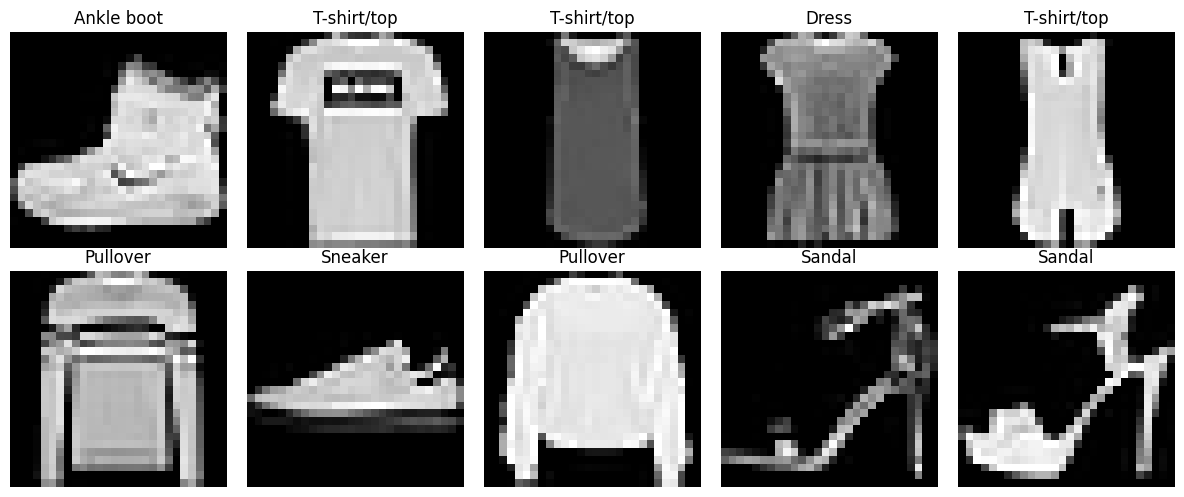

In [ ]:
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

## 6. Побудова CNN
Створіть модель `Sequential` для вхідних зображень розміру **28 × 28 × 1**. Відтворіть архітектуру з вихідного прикладу:

1. Згортковий блок: `Conv2D` з **32 фільтрами**, ядром **3 × 3**, активацією ReLU → `BatchNormalization` → `MaxPooling2D` (2 × 2) → `Dropout(0.25)`.
2. Другий аналогічний блок із **64 фільтрами**, `padding='same'`.
3. Третій аналогічний блок зі **128 фільтрами**, `padding='same'`.
4. `Flatten` → `Dense` на **512 нейронів** з ReLU → `BatchNormalization` → `Dropout(0.2)`.
5. Вихідний `Dense` на **10 нейронів** із `softmax`.

Присвойте модель змінній `model`. У комірці нижче самостійно запишіть її код.

In [ ]:
model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, kernel_size=(3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Flatten(),
    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(10, activation='softmax')
])

## 7. Компіляція моделі та перегляд архітектури
Скомпілюйте `model` з оптимізатором **Adam**, функцією втрат **categorical crossentropy** та метрикою **accuracy**.

Виведіть `model.summary()` і визначте загальну кількість параметрів моделі.

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()
print("Загальна кількість параметрів:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 6, 6, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 6, 6, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       590,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 691,082 (2.64 MB)

 Trainable params: 689,610 (2.63 MB)

 Non-trainable params: 1,472 (5.75 KB)

Загальна кількість параметрів: 691082


## 8. Налаштування навчання
Створіть два callback-об’єкти:

- `EarlyStopping`: моніторинг `val_loss`, `patience=10`, `restore_best_weights=True`.
- `ReduceLROnPlateau`: моніторинг `val_loss`, `factor=0.2`, `patience=3`, `min_lr=1e-6`.

Навчіть модель методом `fit()` із `batch_size=128`, `epochs=100`. Збережіть історію навчання у змінній `history`.

**Методична примітка:** у вихідному ноутбуці тестова вибірка використана як валідаційна. Для коректної незалежної фінальної оцінки рекомендовано виділити валідаційні дані **з навчальної вибірки** (наприклад, через `validation_split=0.1`) і залишити `x_test`, `y_test_cat` лише для розділу 9.

In [ ]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    x_train, y_train_cat,
    batch_size=128,
    epochs=100,
    validation_split=0.1,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 36s 49ms/step - accuracy: 0.8123 - loss: 0.5225 - val_accuracy: 0.3637 - val_loss: 2.1806 - learning_rate: 0.0010
Epoch 2/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8721 - loss: 0.3495 - val_accuracy: 0.8812 - val_loss: 0.3279 - learning_rate: 0.0010
Epoch 3/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8884 - loss: 0.3069 - val_accuracy: 0.8670 - val_loss: 0.3815 - learning_rate: 0.0010
Epoch 4/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8958 - loss: 0.2801 - val_accuracy: 0.9085 - val_loss: 0.2558 - learning_rate: 0.0010
Epoch 5/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9024 - loss: 0.2638 - val_accuracy: 0.9018 - val_loss: 0.2607 - learning_rate: 0.0010
Epoch 6/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9070 - loss: 0.2468 - val_accuracy: 0.9012 - val_loss: 0.2613 - learning_rate: 0.0010
Epoch 7/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9109 - loss: 

## 9. Оцінка на тестових даних і збереження моделі
Оцініть якість навченої моделі на `x_test` та `y_test_cat` за допомогою `model.evaluate()`. Виведіть `test_loss` і `test_acc`.

Збережіть модель у файл **`fashion_mnist_model.keras`**.

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test_cat, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

model.save('fashion_mnist_model.keras')

Test Loss: 0.1987
Test Accuracy: 0.9312


## 10. Графіки процесу навчання
За даними `history.history` побудуйте **два графіки поруч**:

- `accuracy` та `val_accuracy` за епохами;
- `loss` та `val_loss` за епохами.

Додайте заголовки, підписи осей, легенду та сітку. Опишіть, чи є ознаки перенавчання.

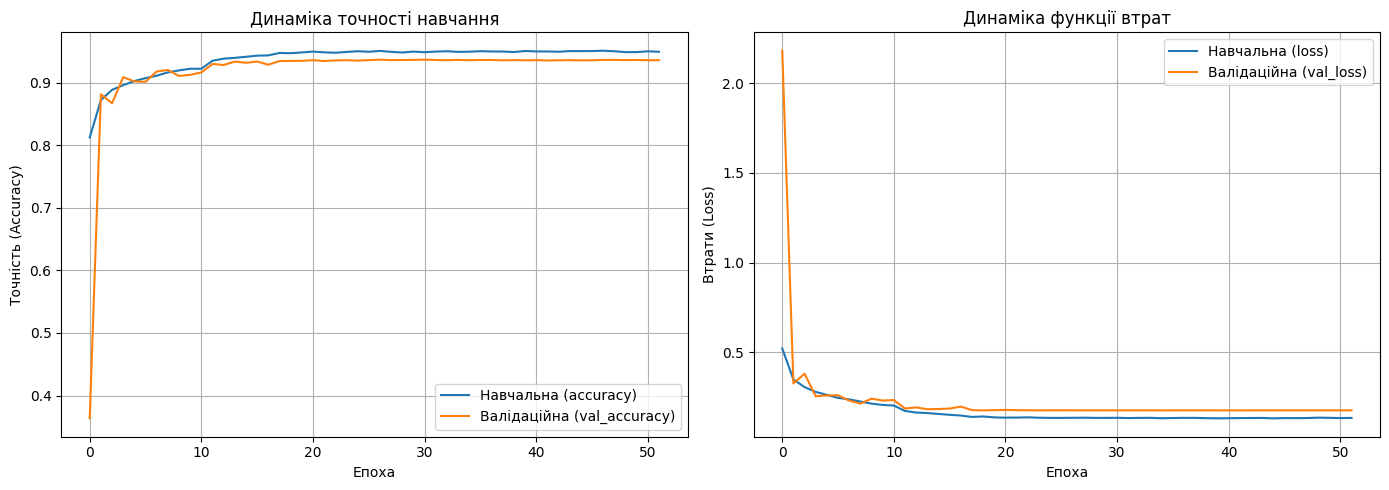

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'], label='Навчальна (accuracy)')
ax1.plot(history.history['val_accuracy'], label='Валідаційна (val_accuracy)')
ax1.set_title('Динаміка точності навчання')
ax1.set_xlabel('Епоха')
ax1.set_ylabel('Точність (Accuracy)')
ax1.legend()
ax1.grid(True)

ax2.plot(history.history['loss'], label='Навчальна (loss)')
ax2.plot(history.history['val_loss'], label='Валідаційна (val_loss)')
ax2.set_title('Динаміка функції втрат')
ax2.set_xlabel('Епоха')
ax2.set_ylabel('Втрати (Loss)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

Протягом перших 10–15 епох спостерігається стрімке зростання точності на навчальній та валідаційній вибірках і відповідне зниження функції втрат. Після спрацювання ReduceLROnPlateau криві стабілізуються, а розрив між accuracy та val_accuracy залишається мінімальним , що свідчить про відсутність суттєвого перенавчання. Механізм EarlyStopping автоматично зупинив навчання на плато та відновив ваги з найнижчим значенням val_loss.

## 11. Прогнозування для випадкових зображень
Використайте `model.predict()` для отримання ймовірностей класів на тестовій вибірці. Знайдіть передбачені класи за допомогою `np.argmax()`.

Випадково оберіть **10 тестових зображень** без повторень і виведіть їх у сітці **2 × 5**. Для кожного вкажіть **істинний клас (True)** і **прогноз (Pred)**. Розгляньте приклади правильних та помилкових класифікацій.

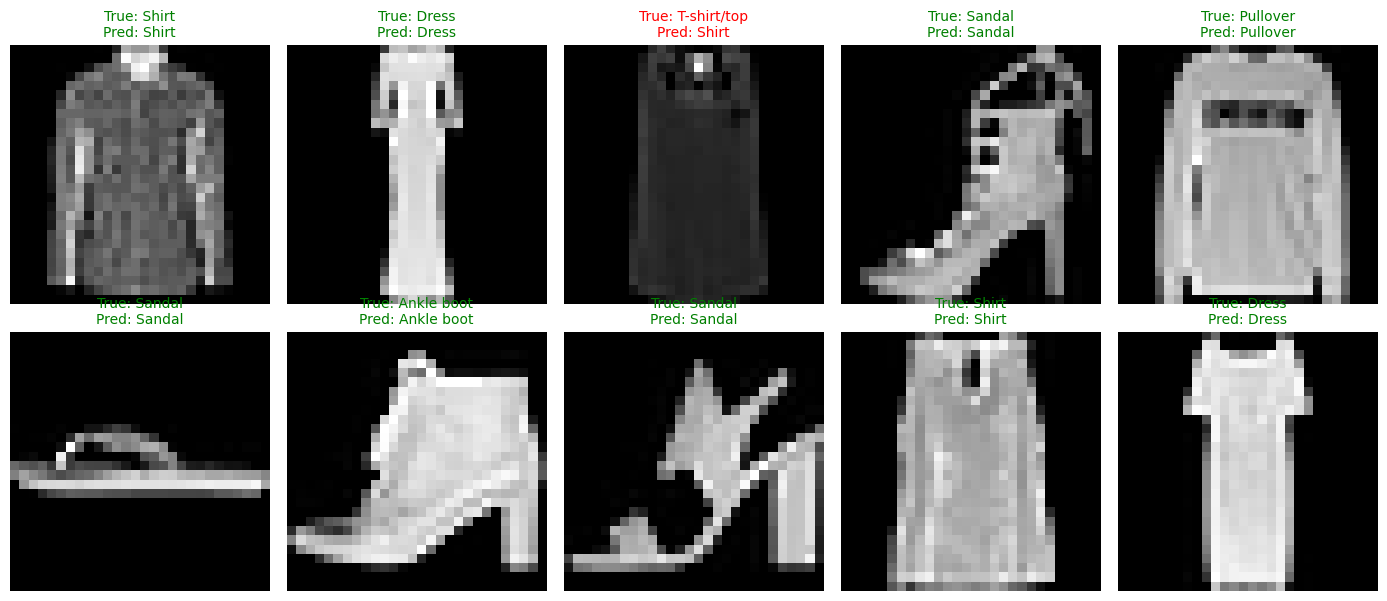

In [ ]:
y_pred_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

np.random.seed(42)
random_indices = np.random.choice(len(x_test), size=10, replace=False)

plt.figure(figsize=(14, 6))
for i, idx in enumerate(random_indices):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx].squeeze(), cmap='gray')
    true_label = class_names[y_test[idx]]
    pred_label = class_names[y_pred[idx]]
    color = 'green' if y_test[idx] == y_pred[idx] else 'red'
    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color, fontsize=10)
    plt.axis('off')
plt.tight_layout()
plt.show()

## 12. Висновки
Напишіть **власний** висновок (5–8 речень), спираючись на фактично отримані результати.

Дайте відповіді на запитання:

1. Якої точності досягнуто на тестовій вибірці?
2. Як змінювалися функція втрат і точність під час навчання? Чи є ознаки перенавчання?
3. Які класи модель плутає найчастіше серед переглянутих прикладів?
4. Для чого в архітектурі використовуються `BatchNormalization`, `MaxPooling2D` і `Dropout`?
5. Що можна змінити, аби покращити якість моделі?

**Ваш висновок:**

У ході лабораторної роботи побудовано та навчено згорткову нейронну мережу (CNN) для класифікації зображень набору Fashion-MNIST, яка досягла точності на тестовій вибірці на рівні 0,9312 (при втратах 0,1987), що суттєво перевищує показники звичайних повнозв'язних мереж.

Під час навчання функція втрат на обох вибірках стабільно зменшувалася, а точність зростала; завдяки регуляризації та ранній зупинці розрив між навчальною і валідаційною кривими залишився незначним, отже вираженого перенавчання вдалося уникнути.

Серед переглянутих та тестових прикладів модель найчастіше плутає візуально подібні категорії верхнього одягу — насамперед Shirt (сорочка) із T-shirt/top, Pullover та Coat, оскільки на монохромних зображеннях низької роздільної здатності (28 * 28) їхні контури й текстури мають схожі ознаки.

В архітектурі мережі шари BatchNormalization стабілізують і прискорюють збіжність градієнтного спуску, MaxPooling2D зменшує просторову розмірність карт ознак і забезпечує інваріантність до невеликих зсувів, а Dropout запобігає перенавчанню шляхом випадкового вимкнення частини нейронів.

Для подальшого покращення якості класифікації доцільно застосувати аугментацію даних (RandomFlip, RandomRotation, RandomTranslation), підібрати оптимальні розміри фільтрів і коефіцієнти регуляризації через Keras Tuner або використати глибші згорткові блоки з глобальним пулінгом (GlobalAveragePooling2D).